# Finding and Analzying Growth Stocks to Support Investment Decisions

# Introduction
The aim of this project is to gather growth stocks from Investopedia, run a webspider to collect relevant context related to the companies and sectors, then use NLP to analyze the stock(s) with the most context.

### Ojectives:
- Define growth stocks
- Use a webscraper to collect growth stocks from Investopedia
- Use a websprider to gather data about the suggested stocks
- Prepare and Analyse data

### Table of Content
- SQLight Database
  - Create tables
  - Class to handle database queries

# Growth Stocks

#### What Is a Growth Stock?
A growth stock is any share in a company that is anticipated to grow at a rate significantly above the average growth for the market$^1$

#### What are the benefits of investing in growth stocks?
These companies typically reinvest their earnings into the business to fuel further expansion, which often leads to impressive revenue and profit growth over time.

# Ethical Considerations
Wescraper...

---

# SQLight Database
Ceate a database to store data which will be analysed later. 

Considerations:
- Rarely, but it can happen that one company has more tickers
- When looking for tickers, it may not be possible to scrape company name and sector from the texts at first, so those are optional, can be filled with later searches
- Context is text scraped from where the company and/or sector was mentioned if exists
- Link is the URL of the website where the ccompany and/or sector was mentioned if exists

<div align="left">
    
| Tables         | Columns                                      |
|:---------------|:---------------------------------------------|
| **stock_info** | Ticker - text, primary key  |
|               | Company name - optional text  |
|               | Sector - optional text  |
|               | Investopedia_link - optional text  |
| **company_context** | Company - text, primary key  |
|               | Context - optional text  |
|               | Link - optional text  |
| **sector_context** | Sector - text, primary key  |
|               | Context - optional text  |
|               | Link - optional text  |

</div>

## Create tables

In [1]:
import sqlite3 as sql

# To avoid conflict with different versions
%config SqlMagic.style = 'Default'
%reload_ext sql

In [2]:
%%sql sqlite:///stockAnalysis.db
CREATE TABLE IF NOT EXISTS stock_info(
    ticker VARCHAR(10) NOT NULL UNIQUE,
    company TEXT,
    sector VARCHAR(100),
    investopedia_link TEXT
);

Done.


[]

In [3]:
%%sql sqlite:///stockAnalysis.db
CREATE TABLE IF NOT EXISTS company_context(
    company TEXT,
    context TEXT,
    link TEXT
);

Done.


[]

In [4]:
%%sql sqlite:///stockAnalysis.db
CREATE TABLE  IF NOT EXISTS sector_context(
    sector VARCHAR(100),
    context TEXT, 
    link TEXT
);

Done.


[]

##### Show created tables

In [5]:
%%sql sqlite:///stockAnalysis.db
SELECT name
FROM sqlite_master
WHERE type='table';

Done.


name
stock_info
company_context
sector_context


## Class to handle database queries

In [6]:
from io import StringIO
from contextlib import redirect_stdout
import inspect
import sqlite3
import pandas as pd

STOCK_DB = "%sql sqlite:///stockAnalysis.db"
MOCK_DB = "%sql sqlite:///:memory:"

class StockAnalysisDB:
    debug = None
    mock_db = None

    def __init__(self, mock_db = False, debug = False):
        self.debug = debug
        self.mock_db = mock_db

    def validate_dict_raise(self, data):
        if not (isinstance(data, list) and all(isinstance(row, dict) for row in data)):
            raise TypeError("Data is not a list of dictionaries")

    
    def call_query(self, query):
        if self.debug:
            print(f"{self.__class__.__name__}.{inspect.currentframe().f_code.co_name}")
    
        # sql magic doesn't throw just writes to stdout
        ret = None
        output = StringIO()
        with redirect_stdout(output):
            if self.mock_db:
                if self.debug:
                    print(f"mock db is used")
                ret = %sql sqlite:///:memory: {query}
            else:
                if self.debug:
                    print(f"stock db is used")
                ret = %sql sqlite:///stockAnalysis.db {query}
        
        msg = output.getvalue()
        if self.debug:
            print(f"{self.__class__.__name__}.{inspect.currentframe().f_code.co_name}")
        
        if 'sqlite3.OperationalError' in msg:
            raise sql.OperationalError(msg)

        if 'sqlite3.IntegrityError' in msg:
            raise sql.IntegrityError(msg)

        return ret
    
    def insert_into(self, table, data):
        ## Make an SQL-injection check for table and data!!
        try:
            # data must be a list of dictionaries
            self.validate_dict_raise(data)
            
            queries = []
            for row in data:
                columns = ", ".join(row.keys())
                values = ", ".join(
                    f"'{v}'"
                    if isinstance(v, str) and v != "N/A" else "NULL"
                    for v in row.values()
                )
                query = f"INSERT INTO {table} ({columns}) VALUES({values});" 
                self.call_query(query)
        
        except TypeError as e:
            print(e)
        except sql.OperationalError as e:
            print(f"SQL insert into Failed due to operation error: {e}")
            raise

        except sql.IntegrityError as e:
            print(f"SQL insert into failed due to integrity error: {e}")
            raise

    def select(self, table, columns = None, where = None):
        try:
            query = "SELECT "
            
            if columns:
                query +=", ".join(columns)
            else:
                query += "*"
            
            query +=" FROM " + table

            if where:
                query +=" WHERE " + where;
            
            query += ";"
            return self.call_query(query)
            
        except TypeError as e:
            print(e)
        except sql.OperationalError as e:
            print(f"SQL Select Failed due to operation error: {e}")
            raise
        except sql.IntegrityError as e:
            print(f"SQL Select failed due to integrity error: {e}")
            raise

In [7]:
# Create an instance which will be injected
stock_db = StockAnalysisDB(mock_db=False)

# Class to handle, clean and transform data
- Fetches raw data from DB
- Cleans missing values, standardizes formats
- Prepare for analysis: filtering, removing duplicates

In [85]:
import pandas as pd
import pycountry
import tldextract
from bs4 import BeautifulSoup
from urllib.parse import urlparse
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

BASE_URL = "https://www.investopedia.com/the-best-growth-stocks-8783031"

class StockDataHandler():
    stock_db = None
    debug = None
    
    ## Domain-based data ##

    NEWS_LINKS = {
        "https://seekingalpha.com/article/4764473-gorilla-technology-stock-after-250-percent-run-time-to-sell",
        "https://www.stocktitan.net/news/GRRR/gorilla-technology-secures-landmark-1-8-billion-agreement-to-drive-fb8309p88jhb.html",
        "https://www.investing.com/news/company-news/grrr-stock-soars-to-52week-high-hits-2603-amidst-strong-growth-93CH-3868140",
        "https://finance.yahoo.com/news/gorilla-sets-record-straight-baseless-201300250.html",
        "https://seekingalpha.com/news/4418114-gorilla-technology-group-sinks-after-bear-cave-cautious-report",
        "https://stockstotrade.com/news/organogenesis-holdings-inc-orgo-news-2025_02_28/",

        # Blogs
        "https://www.fool.com/investing/",
        "https://www.stockgumshoe.com/",
        "https://www.insidermonkey.com/blog/",
         
        # More general news sides
      # "https://uk.investing.com/news/company-news", "https://www.stocktitan.net/news",
      # "https://www.gurufocus.com/news", "https://www.insidermonkey.com/blog",
      # "https://www.fool.co.uk/2025", "https://uk.investing.com/news/company-news",
      # "https://www.investing.com/news/company-news", "https://simplywall.st/stocks/",
      # "https://seekingalpha.com/article", "https://www.tradingview.com/symbols",
      # "https://www.marketbeat.com/stocks", "https://newsable.asianetnews.com/markets", "https://www.stockstelegraph.com/"
          
        "https://stockanalysis.com/",
        "https://www.zacks.com/"
    }

    WANTED_PATH_SEGMENTS = {
        # Sectors
        'technology', 'health-technology','health_technology', 'technology-services', 'technology_services', 'finance', 
        
        'growth', 'company', 'sector', 'stock', 'news', 'analysis', 'report', 'press', 'overview', 'financial', 'blog', 'ticker',
        'guidance', 'result', 'outlook', 'market', 'trend', 'corporate', 'strategy', 'research', 'article',
    }

    UNWANTED_PATH_SEGMENTS = {
        "login", "signup", "profile", "checkout", "contact", "privacy", "terms", "careers", "screener", "market-movers", "quotes",
        "tel:", "javascript", "advert", "politics", "legal", "mail", "help", "login", "account", "logout",
        
         # Experimentation
         "forum",
         "sport",
         ".pdf",
         "/video/"
    }

    SOCIAL_DOMAINS = {
        "facebook.com", "twitter.com", "x.com", "linkedin.com", "youtube.com", "instagram.com", "tiktok.com"
    }

    COUNTRY_CODES_2 = {country.alpha_2 for country in pycountry.countries}
    COUNTRY_CODES_3 = {country.alpha_3 for country in pycountry.countries}

    def __init__(self, db, debug = False):
        self.stock_db = db
        self.debug = debug

        # Domain
        self.__company_keywords = set()
        self.__sector_keywords = set()

        # Data cleaning
        self.stop_words = set(stopwords.words('english'))
        self.lemmatizer = WordNetLemmatizer()
    
    # Remove not-needed legal endings
    def simplify_company_names(self, company_data):

        # has to be a list because order is important!
        LEGAL_ENDINGS = [
             ' Group Inc.', 'Group, Inc.'
             ' Holdings Inc.',' Holdings, Inc.',
             ' Holdings Limited',' International Limited',
             ' Holdings LLC',' International Limited',
             ' S.A.',' Corp.',' Co.',', Inc.',' Inc.'
        ]

        # For sets
        if isinstance(company_data, set) or isinstance(company_data, list):
            clean_data = set()
            for company in company_data:
                for ending in LEGAL_ENDINGS:
                    company = re.sub(re.escape(ending), '', company, flags=re.IGNORECASE)
                clean_data.add(company.strip())
            return clean_data

        # For df column
        elif isinstance(company_data, pd.Series):
            clean_series = company_data.copy()
            for ending in LEGAL_ENDINGS:
                clean_series = clean_series.str.replace(re.escape(ending), '', case=False, regex=True)
            return clean_series.str.strip()

        else:
            raise TypeError("Input must be a set or pandas Series")

    # Skip links that are not related to news, articles
    def is_link_might_be_useful(self, link):
        if not isinstance(link, str):
            return False

        parsed = urlparse(link)
        domains = parsed.netloc.split('.')

        # Skip language links
        for part in domains:
            if part == "com":
                continue

            extr = tldextract.extract(parsed.netloc)
            subdomains = extr.subdomain.split('.')
            for part in subdomains:
                if part.upper() in self.COUNTRY_CODES_2 or part.upper() in self.COUNTRY_CODES_3:
                    if self.debug:
                        print(f"Skipping country-specific subdomain: {part}")
                    return False
            
            # Skip language paths
            path_segments = [seg for seg in parsed.path.strip("/").split("/") if seg]
            for seg in path_segments:
                if seg.upper() in self.COUNTRY_CODES_2 or seg.upper() in self.COUNTRY_CODES_3:
                    if self.debug:
                        print(f"Skipping country code in path: {seg}")
                    return False
                    
        if any(social in parsed.netloc for social in self.SOCIAL_DOMAINS):
            return False
            
        if any(seg in parsed.path.lower() for seg in self.UNWANTED_PATH_SEGMENTS):
            return False
            
        if parsed.scheme not in ("http", "https"):
            return False
        
        return True

    # We expect the stock_info table to be filled
    def get_data_as_keyword_from_db(self, columns=['ticker', 'company', 'sector']):
        
        data_df = self.stock_db.select("stock_info", columns).DataFrame()
        if data_df.empty:
            raise ValueError("Stock_info table is empty!")
        
        data_df = data_df.fillna("")
        
        # Sectors are too general, adding the text 'sector' will help with contex
        if 'sector' in data_df.columns:
            data_df['sector'] = data_df['sector'].apply(lambda s: s+ " sector")
        
        flattened_df = set(data_df.values.flatten())
        flattened_df.discard(" sector")                   
        flattened_df.discard("")

        # lower for case-insensitivity
        flattened_df = [e.lower() for e in flattened_df]
        return self.simplify_company_names(flattened_df)

    # At this state of the project the tickers won't change, so we can do this boosting
    def get_company_keywords(self):
        if len(self.__company_keywords) == 0:
            self.__company_keywords = self.get_data_as_keyword_from_db(['ticker', 'company'])
        return self.__company_keywords          

    def get_sector_keywords(self):
        if len(self.__sector_keywords) == 0:
            self.__sector_keywords = self.get_data_as_keyword_from_db(['sector'])
        return self.__sector_keywords          
    
    # Return keyword otherwise None
    def get_keyword_if_link_contains(self, link, keywords):
        
        keywords = {k.replace(' ', '-') for k in keywords} | {k.replace(' ', '_') for k in keywords}        
        pattern = r'(?<![a-zA-Z])(' + '|'.join(map(re.escape, keywords)) + r')(?=[^a-zA-Z]|$)'

        match = re.search(pattern, link, re.IGNORECASE)
        if match:
            return match.group(0).replace('-', ' ').replace('_', ' ') 

        return None   

    def get_company_keyword_if_link_contains(self, link):
        if not isinstance(link, str):
            return None
        keywords = self.get_company_keywords()
        return self.get_keyword_if_link_contains(link, keywords)

    def get_sector_keyword_if_link_contains(self, link):
        if not isinstance(link, str):
            return None
        keywords = self.get_sector_keywords()
        return self.get_keyword_if_link_contains(link, keywords)


    ## Data Cleaning ##

    def select_data_as_df(self, table):
        return pd.DataFrame(self.stock_db.select(table))

    def clean_context_for_query(self, context):
        if not isinstance(context, str):
            raise ValueError(f"context is not string: {context}")
    
        # Remove quotes, markers
        invalid_chars = ["’", "‘", "‛", "`", "´", "'", "\n", "\t", ";", "\\", "\0"]
        for i in invalid_chars:
            context = context.replace(i, " ")

        context = ' '.join(context.split())

        return context

    def clean_text_and_remove_stop_words(self, text):
        if pd.isna(text):
            return ""

        # Remove HTML tags
        text = BeautifulSoup(text, 'html.parser').get_text()

        # Remove URLs and special characters
        text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
        text = re.sub(r"[^a-zA-Z0-9\s$€£¥.,!?%]", ' ', text)
        
        # Lowercase and remove stopwords
        words = text.lower().split()
        words = [self.lemmatizer.lemmatize(w) for w in words if w not in self.stop_words]

        return ' '.join(words)

    def clean_context_data(self, df):

        # Drop duplicates
        df = df.drop_duplicates(subset=['context']).copy()

        # Remove tags and special characters (except for currencies)
        df['context'] = df['context'].apply(self.clean_text_and_remove_stop_words)

        return df

    @staticmethod
    def replace_ticker_with_company(row, ticker_to_company):
        # Check if the company value is a ticker
        if row['company'].upper() in ticker_to_company:
            return ticker_to_company[row['company'].upper()]
        return row['company']

    def clean_company_col_in_context(self, df, stock_info_df):
        # Change ticker to company name
        ticker_to_company = dict(zip(stock_info_df['ticker'], stock_info_df['company']))
        df['company'] = df.apply(
            lambda row: self.replace_ticker_with_company(row, ticker_to_company),
            axis=1)

        # Remove legal endings
        df['company'] = self.simplify_company_names(df['company'])

        # Format company names
        df['company'] = [name.title() for name in df['company']]
        
        return df

In [86]:
data_handler = StockDataHandler(db=stock_db)

# Class for Web Spider
I will gather data from the Internet using a Webscraper:
- Tickers mentioned as good investment oportunities, whenever possible I will also save the company and sector
- I will save context from atricles about the company, and the sector

## Webscraper
- Gather growth stocks from Investopedia
- Identify the tickers in the artices
- Store data gathered in a database


In [87]:
import re
import http.client
from urllib.request import urlopen
from urllib.request import Request
from urllib.error import HTTPError, URLError
from urllib.parse import urljoin
from urllib.parse import urlparse
from furl import furl
from bs4 import BeautifulSoup
import time
import random

USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/88.0.4324.182 Safari/537.36"
]

def get_bs_from_url(url):
    try:
        headers = {
            "User-Agent": random.choice(USER_AGENTS),
            "Referer": "https://www.google.com/", # simulate Google search
            "Connection": "keep-alive",
            "Upgrade-Insecure-Requests": "1"
        }
        
        # To avoid 'Too many requests' and not detectors
        time.sleep(0.2 + random.uniform(1, 3))

        response = urlopen(Request(url, headers=headers),
                           timeout=30)
        return BeautifulSoup(response.read(), 'html.parser')

    except HTTPError as e:
        print(f"HTTP error: {e.code} - {e.reason}")
        return None
    
    except URLError as e:
        print(f"URL error for {url}: {e.reason}")
        return None

    except http.client.RemoteDisconnected:
        print("RemoteDisconnected: Remote host closed the connection.")
        return None

    except http.client.IncompleteRead as e:
        # e.partial contains whatever was successfully read
        html = e.partial
        print("Warning: IncompleteRead - partial response used.")
        return BeautifulSoup(html, 'html.parser')

    except ValueError as e:
        print(f"ValueError for {url}: {e}")
        return None

    except Exception as e:
        print(f"General error occured:{e}")


In [88]:
from collections import defaultdict
from collections import deque

class InvestopediaWebSpider:
    MAX_VISITED_LINKS = 10000
    data_handler = None
    debug = None

    # BFS
    visited_links = set()
    company_link_context_map = defaultdict(lambda: defaultdict(set))
    sector_link_context_map = defaultdict(lambda: defaultdict(set))

    def __init__(self, dh, debug = False):
        self.data_handler = dh
        self.debug = debug
        
        self.bs = get_bs_from_url(BASE_URL)
        if not self.bs:
            raise ValueError("BeautifulSoup is not existing, the class can't be initiatied")

    ## Utility functions ##

    @staticmethod
    def convert_if_relative_URL(base_url, rel_url):
        if not isinstance(rel_url, str):
            return None

        if not rel_url.isascii():
            return None

        # return None for javascript as it's not a link
        if rel_url.lower().startswith("javascript:"):
            return None

        # If empty, references the base url
        if rel_url == "":
            return base_url

        # Just return if not relative
        if urlparse(rel_url).scheme:
            return rel_url

        if not isinstance(base_url, str) or not base_url:
            return None

        # Use scheme
        if rel_url.startswith("//"):
            base_scheme = urlparse(base_url).scheme
            if not base_scheme:
                print("Base URL has no scheme, cannot resolve `//` link.")
                return None
            return f"{base_scheme}:{rel_url}"

        if rel_url.startswith("#"):
            return urljoin(base_url, rel_url)
        
        parsed_base = urlparse(base_url)
        if parsed_base.path and not parsed_base.path.endswith('/'):
            base_url = parsed_base._replace(path=parsed_base.path + '/').geturl()

        return urljoin(base_url, rel_url)
                
    # Remove query params
    @staticmethod
    def normalize_url(base_link, url):
            
        # Convert references to full URLs
        # Returns none if not valid URL
        url = InvestopediaWebSpider.convert_if_relative_URL(base_link, url)
        if not url:
            return None

        try:
            f = furl(url)
            f.args = {}
            f.fragment = ''
        except ValueError as e:
            print("ValueError raised from normalize_url: {e}")
            return None

        return f.url
 
    ## Scraper functions ##
    
    def scrape_ticker_data_from_investopedia(self):
        # Look for the table with the world 'stock'
        table = None
        for tbl in self.bs.find_all("table"):
            if tbl.find("th", string=lambda s: s and "stock" in s.lower()):
                table = tbl
                break

        if table:
            # First row of the table body contains the indexes
            first_row = table.find("tbody").find("tr")
            column_name_indexes = {}
            for i, td in enumerate(first_row.find_all("td", recursive=False)):
                text = td.get_text(strip=True).lower()
                if "ticker" in text:
                    column_name_indexes["ticker"] = i
                elif "company" in text:
                    column_name_indexes["company"] = i
                elif "sector" in text:
                    column_name_indexes["sector"] = i
                i+=1

            # Get next data from table
            all_ticker_data = []
            for row in first_row.find_next_siblings("tr"):
                ticker_data = {}
                cells = row.find_all("td")
                
                # Ticker has a link to the profile
                link = cells[column_name_indexes["ticker"]].find('a')
                if link:
                    ticker_data["investopedia_link"] = link.attrs['href']
                
                # Extract data from each cell
                ticker_data["ticker"] = cells[column_name_indexes["ticker"]].get_text(strip=True)
                ticker_data["company"] = cells[column_name_indexes["company"]].get_text(strip=True)
                ticker_data["sector"] = cells[column_name_indexes["sector"]].get_text(strip=True)

                all_ticker_data.append(ticker_data)

            self.data_handler.stock_db.insert_into("stock_info", all_ticker_data)

    def insert_company_context(self):
        if not self.company_link_context_map:
            return

        company_records = []
        for keyword, links in self.company_link_context_map.items():
            for link, contexts in links.items():
                for context in contexts:
                    company_records.append({
                        'company': keyword,
                        'link': link,
                        'context': self.data_handler.clean_context_for_query(context)
                    })
        self.data_handler.stock_db.insert_into('company_context', company_records)
        self.company_link_context_map.clear()

    def insert_sector_context(self):
        if not self.sector_link_context_map:
            return
            
        sector_records = []
        for keyword, links in self.sector_link_context_map.items():
            for link, contexts in links.items():
                for context in contexts:
                    sector_records.append({
                        'sector': keyword,
                        'link': link,
                        'context': self.data_handler.clean_context_for_query(context)
                    })
        self.data_handler.stock_db.insert_into('sector_context', sector_records)
        self.sector_link_context_map.clear()
    
    # Scrapes the BeautifulSoup for any occurrence of tickers, companies and sector.
    # If a keyword is found in a header, it also collects the next paragraph.
    # Stores the context in the database.
    def scrape_context_for_keywords(self, bs, link): 
        company_keywords = self.data_handler.get_company_keywords()
        sector_keywords = self.data_handler.get_sector_keywords()

        elements = bs.find_all(['h1', 'h2', 'h3', 'h4', 'h5', 'h6', 'p'])
        for i, e in enumerate(elements):
            text = e.get_text(separator=" ", strip=True)
            
            for keyword in company_keywords:
                # test with regex if it's a match (important for tickers as they are very small)
                if re.search(r'\b' + re.escape(keyword) + r'\b', text, re.IGNORECASE):    
                    if self.debug:
                        print(f"HTML context has company keyword")

                    # If found it, gather all text from siblings and under
                    text_from_siblings_and_under = ""
                    for sibling in e.find_next_siblings():
                        text_from_siblings_and_under += sibling.get_text(separator=" ", strip=True)
                    
                    limited_text = (text + " " + text_from_siblings_and_under)[:1000]
                    self.company_link_context_map[keyword][link].add(limited_text)

            for keyword in sector_keywords:
                # test with regex if it's a match (important for tickers as they are very small)
                if re.search(r'\b' + re.escape(keyword) + r'\b', text, re.IGNORECASE):    
                    if self.debug:
                        print(f"HTML context has sector keyword")

                    # If found it, gather all text from siblings and under
                    text_from_siblings_and_under = ""
                    for sibling in e.find_next_siblings():
                        text_from_siblings_and_under += sibling.get_text(separator=" ", strip=True)
                    limited_text = (text + " " + text_from_siblings_and_under)[:1000]
                    self.sector_link_context_map[keyword][link].add(limited_text)
    
    def collect_context_with_spider_BFS(self, max_depth = 2, max_exploring_link = 10):
        if self.debug:
                print(f"{self.__class__.__name__}.{inspect.currentframe().f_code.co_name}")

        # Use FIFO for BFS
        queue = deque(self.data_handler.NEWS_LINKS)
        self.visited_links.clear()

        depth = 0
        while queue and depth <= max_depth and len(self.visited_links) <= self.MAX_VISITED_LINKS:
            print(f"\n--- depth = {depth} ---\n")
            depth += 1

            level_size = len(queue)
            
            for level in range(level_size):
                if self.debug:
                    print(f"level: {level}")
                    
                if not queue or len(self.visited_links) > self.MAX_VISITED_LINKS:
                    break

                # Add data to DB if not empty
                self.insert_company_context()
                self.insert_sector_context()

                current_link = queue.popleft()            
                if current_link in self.visited_links:
                    if self.debug:
                        print("current link is visited, skipping it")
                    continue
    
                print(f"Processing {current_link} (...)")
                bs = get_bs_from_url(current_link)
                if not bs:
                    self.visited_links.add(current_link)
                    if self.debug:
                        print("bs is None")
                    continue

                # Add all text if link is about ticker/company
                company_kw = self.data_handler.get_company_keyword_if_link_contains(current_link)
                if company_kw:
                    self.company_link_context_map[company_kw][current_link].add(bs.get_text()[:1000])
                    self.visited_links.add(current_link)
                    if self.debug:
                        print(f"company keyword found, added: {company_kw}")
                    continue

                # Add all text if link is about sector
                sector_kw = self.data_handler.get_sector_keyword_if_link_contains(current_link)
                if sector_kw:
                    self.sector_link_context_map[sector_kw][current_link].add(bs.get_text()[:1000])
                    self.visited_links.add(current_link)
                    if self.debug:
                        print(f"Sector keyword found, added: {sector_kw}")
                    continue

                self.visited_links.add(current_link)
                self.scrape_context_for_keywords(bs, current_link)

                limit = 0
                for link in bs.find_all('a'):
                    if limit == max_exploring_link:
                        break
                    
                    if 'href' in link.attrs:
                        link_text = self.normalize_url(current_link, link['href'])
                        
                        if self.debug:
                            print(f"Link found: {link_text}")
                        
                        if link_text and link_text not in self.visited_links \
                            and self.data_handler.is_link_might_be_useful(link_text) \
                            and link_text not in queue:

                            limit += 1
                            
                            if self.debug:
                                print(f"considered useful: {link_text}")

                            # Only prioritize after the first level
                            if depth == 1:
                                 queue.append(link_text)
                            else:
                                if any(kw in link_text.lower() for kw in self.data_handler.WANTED_PATH_SEGMENTS):
                                    queue.appendleft(link_text)
                                    if self.debug:
                                        print(f"Link added with priority")
    
                                else:
                                    queue.append(link_text)
                                    if self.debug:
                                        print(f"Link added without priority")

        self.insert_company_context()
        self.insert_sector_context()

In [89]:
web_spider = InvestopediaWebSpider(dh=data_handler)

In [90]:
%sql sqlite:///stockAnalysis.db "DELETE FROM stock_info"
web_spider.scrape_ticker_data_from_investopedia()
%sql sqlite:///stockAnalysis.db "SELECT * FROM stock_info LIMIT 3"

11 rows affected.
Done.


ticker,company,sector,investopedia_link
GRRR,Gorilla Technology Group Inc.,Technology Services,https://www.investopedia.com/markets/quote?tvwidgetsymbol=GRRR
ORGO,Organogenesis Holdings Inc.,Health Technology,https://www.investopedia.com/markets/quote?tvwidgetsymbol=ORGO
CYD,China Yuchai International Limited,Producer Manufacturing,https://www.investopedia.com/markets/quote?tvwidgetsymbol=CYD


In [91]:
# My DB is already filled, so run this just for a short time here
# web_spider.collect_context_with_spider_BFS(1,1)

In [92]:
%sql sqlite:///stockAnalysis.db "SELECT * FROM company_context LIMIT 1;"

Done.


company,context,link
grrr,"GRRR Stock Soars to 52-Week High, Hits $26.03 Amidst Strong Growth By Investing.comInvesting.com - Financial Markets WorldwideOpen in AppPopular SearchesPlease try another searchGet 45% OffSign InFree Sign UpEnglish (UK)English (India)English (Canada)English (Australia)English (South Africa)English (Philippines)English (Nigeria)DeutschEspañol (España)Español (México)FrançaisItalianoNederlandsPortuguês (Portugal)PolskiPortuguês (Brasil)РусскийTürkçe‏العربية‏ΕλληνικάSvenskaSuomiעברית日本語한국어简体中文繁體中文Bahasa IndonesiaBahasa MelayuไทยTiếng ViệtहिंदीGet 45% OffSign InFree Sign UpMarketsIndicesIndices FuturesMajor IndicesIndices Real-TimeWorld IndicesGlobal IndicesDow Jones FuturesS&P 500 FuturesNasdaq FuturesS&P 500Dow JonesNasdaq 100DAXFTSE 100Euro Stoxx 50Nikkei 225StocksStock ScreenerTrending StocksStocks Picked by AIUnited StatesPre-MarketEarnings CalendarAmericasEurope52 Week High52 Week LowMost ActiveTop GainersTop LosersUndervalued StocksOvervalued StocksWorld ADRsMarijuana StocksTop Ban",https://www.investing.com/news/company-news/grrr-stock-soars-to-52week-high-hits-2603-amidst-strong-growth-93CH-3868140


In [93]:
%sql sqlite:///stockAnalysis.db "SELECT * FROM sector_context LIMIT 1"

Done.


sector,context,link


I have data in company_context, although it's very messy.  
I don't have data in sector_context, I need to adjust the spider to focus more on sector-related data, but for now, I won't use it in my analysis.

# Data Analysis
Use NLP to analyze the context collected for companies and sectors.
Analyze the most frequently used company, and sector
- uses cleaned data from DB
- applies statistics, visualization, ML
- final output: insights

## What will the analysis be focus on?
The analysis focuses on:
- visualize the most frequent words used when mentioning the specific stocks
- analyze the context around the stock's company; is it mostly positive or negative? Probably we don't want to invest in a company which has a negative publicity
- *volatility*: check the difference between the highest and lowest values within a day. Also, examine the difference between the opening and closing prices on the same day, and compare the opening price with the previous day's closing price to see the mood changes while the market is closed.
- *monotonity*: analyze the closing prices to determine the overall trend of the security

### Gather and clean data

In [181]:
# Load data from DB into DataFrame
stock_info_df = data_handler.select_data_as_df("stock_info")
company_context_df = data_handler.select_data_as_df("company_context")
company_context_df.head(3)

,company,context,link
0,grrr,"GRRR Stock Soars to 52-Week High, Hits $26.03 ...",https://www.investing.com/news/company-news/gr...
1,grrr,"GRRR Stock Soars to 52-Week High, Hits $26.03 ...",https://www.investing.com/news/company-news/gr...
2,GRRR,Gorilla Technology Secures Massive $1.8 Billio...,https://www.stocktitan.net/news/GRRR/gorilla-t...


In [195]:
# Clean and format data
clean_df = data_handler.clean_context_data(company_context_df)
clean_df = data_handler.clean_company_col_in_context(clean_df, stock_info_df)
clean_df.head(3)

,company,context,link
0,Gorilla Technology,"grrr stock soar 52 week high, hit $26.03 amids...",https://www.investing.com/news/company-news/gr...
2,Gorilla Technology,gorilla technology secures massive $1.8 billio...,https://www.stocktitan.net/news/GRRR/gorilla-t...
10,China Yuchai,china yuchai international limited nyse cyd q4...,https://www.insidermonkey.com/blog/china-yucha...


## Analysis Class

In [183]:
# Download VADER lexicon
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\kuszk\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [190]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

class StockContextAnalyzer:

    def __init__(self):
        self.analyzer = SentimentIntensityAnalyzer()

    def get_top_mentioned_n(self, df, n=3):
        # Find the top 3 most mentioned company
        top_companies  = df.groupby('company')['context'].count().sort_values(ascending=False).head(3)

        # Convert to DataFrame for better display
        top_companies_df = pd.DataFrame({
            'Company': top_companies.index,
            'Context Count': top_companies.values
        })

        return top_companies_df

    # Sentiment analysis #
    def add_sentiment_scores(self, df):
        df = df.copy()
        df['sentiment'] = df['context'].apply(
            lambda text: self.analyzer.polarity_scores(text)['compound'] if text else 0)
        return df

    # Word frequency analysis #
    
    def get_word_frequency(self, df, company_name, top_n=20):
        company_text = ' '.join(
            df[df['company'].str.lower() == company_name.lower()]
            ['context'].tolist()
        )
        words = company_text.split()
        return Counter(words).most_common(top_n)
    

In [191]:
# Create analyzer
analyzer = StockContextAnalyzer()

In [196]:
# Select the top 3 mentioned companies
top_companies = analyzer.get_top_mentioned_n(clean_df)
top_companies

,Company,Context Count
0,Root,26
1,Gorilla Technology,11
2,Russell 3000,2


In [201]:
# Russell only has 2 context, which won't be representative enough
# Let's use only the other two
clean_df = clean_df[ clean_df['company'].isin(['Gorilla Technology', 'Root'])]

## Sentiment Analysis

In [206]:
clean_df = analyzer.add_sentiment_scores(clean_df)
sentiment_results = clean_df.groupby('company')['sentiment'].mean().reset_index()
sentiment_results.head(3)

,company,sentiment
0,Gorilla Technology,0.366718
1,Root,0.196035


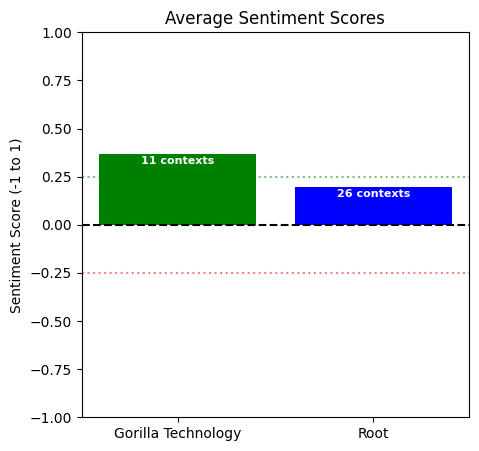

In [219]:
import matplotlib.pyplot as plt

# Visualization
plt.figure(figsize=(5, 5))
plt.bar(sentiment_results['company'], sentiment_results['sentiment'], color=['green', 'blue', 'orange'])
plt.title('Average Sentiment Scores')
plt.ylabel('Sentiment Score (-1 to 1)')
plt.ylim(-1, 1)
plt.axhline(0, color='black', linestyle='--')
plt.axhline(0.25, color='green', linestyle=':', alpha=0.5)
plt.axhline(-0.25, color='red', linestyle=':', alpha=0.5)

for index, value in enumerate(sentiment_results['sentiment']):
    company_name = sentiment_results.iloc[index]['company']
    context_count = clean_df[clean_df['company'] == company_name].shape[0]
    
    plt.text(
        index,                      # x-position
        value - 0.05,               # y-position (below bar top)
        f"{context_count} contexts", 
        ha='center',
        color='white',
        fontweight='bold',
        fontsize=8
    )

plt.show()

Text(0.5, 1.0, 'Sentiment Distribution')

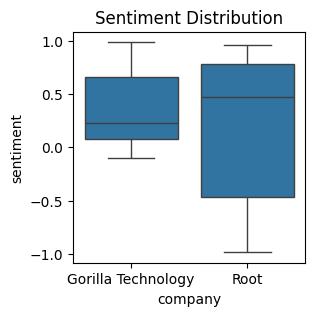

In [213]:
import seaborn as sns
plt.figure(figsize=(3, 3))
sns.boxplot(x='company', y='sentiment', data=clean_df)
plt.title('Sentiment Distribution')

## Wordcounts

### Select the top 3 company for analyzation

C:\Users\kuszk\AppData\Local\Temp\ipykernel_75472\946631249.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Company', y='Context Count', data=top_companies_df, palette='viridis')


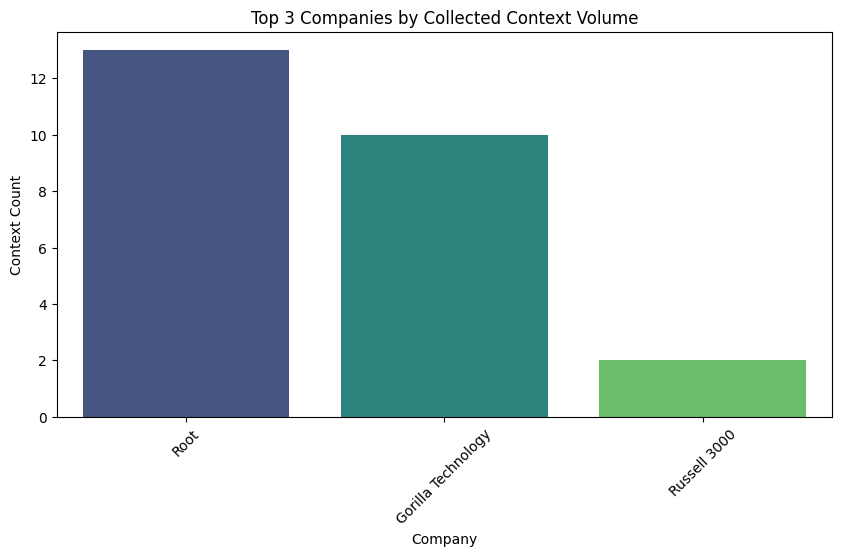

In [248]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization
plt.figure(figsize=(10, 5))
sns.barplot(x='Company', y='Context Count', data=top_companies_df, palette='viridis')
plt.title('Top 3 Companies by Collected Context Volume')
plt.xticks(rotation=45)
plt.show()

In [236]:


# # Partial removal with Fuzzy
# from fuzzywuzzy import process

# def fuzzy_replace_ticker(row, ticker_to_company):
#     best_match, score = process.extractOne(row['company'], ticker_to_company.keys())
#     if score > 80:  # Threshold for match confidence
#         return ticker_to_company[best_match]
#     return row['company']

# company_context_df['company'] = company_context_df.apply(
#     lambda row: fuzzy_replace_ticker(row, ticker_to_company),
#     axis=1
# )

In [131]:
imc

# Sentiment analysis
sent_analyzer = SentimentAnalyzer()
sentiment_results = sent_analyzer.analyze_company_sentiment(clean_df)

# Word frequency
word_analyzer = WordAnalyzer()
word_freq = word_analyzer.get_word_frequency(clean_df, target_company)

val = {
        'sentiment': sentiment_results,
        'word_frequency': word_freq,
        'cleaned_data': clean_df
      }

NameError: name 'SentimentAnalyzer' is not defined

In [ ]:
print(f"Average Sentiment for GRRR: {analysis_results['sentiment'].iloc[0]['sentiment']:.2f}")
print("\nTop 20 Keywords:")
for word, count in analysis_results['word_frequency']:
    print(f"{word}: {count}")

---

## Conclusions
- 

## Possible improvements for the project
1. Work on SQL-inject
2. Schedule with Pipeline
3. Work with sector-related context in analyzation
4. Improve Webspider with e.g. utility measuring, more sophisticated priorization
5. Concurrent BFS

## Difficulties with data
scraper ahh a lot

---

# Unit Tests

### Create mock tables in memory database

In [ ]:
# To avoid conflict with different versions
%config SqlMagic.style = 'Default'
%reload_ext sql

In [ ]:
%%sql sqlite:///:memory:
CREATE TABLE IF NOT EXISTS stock_info(
    ticker VARCHAR(10) NOT NULL UNIQUE,
    company TEXT,
    sector VARCHAR(100),
    investopedia_link TEXT,
    PRIMARY KEY (ticker)
);

In [ ]:
%%sql sqlite:///:memory:
CREATE TABLE IF NOT EXISTS company_context(
    company TEXT,
    context TEXT,  
    link TEXT
);

In [ ]:
%%sql sqlite:///:memory:
CREATE TABLE  IF NOT EXISTS sector_context(
    sector VARCHAR(100),
    context TEXT,  
    link TEXT
);

## Test Database class

In [ ]:
%sql sqlite:///:memory:

import unittest
from io import StringIO
from unittest.mock import patch
import sqlite3 as sql

class TestDatabase(unittest.TestCase):

    def setUp(self):
        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

        # Create mock DB
        self.db = StockAnalysisDB(mock_db=True)

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()

    # Define test type when we expect no exception
    def assertNotRaises(self, exception, func, *args, **kwargs):
        try:
            func(*args, **kwargs)
        except exception as e:
            self.fail(f"Expected no {exception}, but got: {e}")

    def test_db_class_exists(self):
        self.assertIsNotNone(StockAnalysisDB)

    
     ## call_query function ##

    def test_call_query_exists(self):
        self.assertIsNotNone(StockAnalysisDB.call_query)
        
    @patch("__main__.get_ipython")
    def test_call_query_handles_exeptions(self, mock_ipython):

        # Mock an OperationalError
        mock_ipython.return_value.run_line_magic.side_effect = sql.OperationalError("sqlite3.OperationalError: syntax error")
        with self.assertRaises(sql.OperationalError) as context:
            self.db.call_query("INVALID SQL")
        self.assertIn("sqlite3.OperationalError", str(context.exception))

        # Mock an IntegrityError
        mock_ipython.return_value.run_line_magic.side_effect = sql.IntegrityError("sqlite3.IntegrityError: unique constraint failed")
        with self.assertRaises(sql.IntegrityError) as context:
            self.db.call_query("INSERT INTO stock_info VALUES ('XXX')")
        self.assertIn("sqlite3.IntegrityError", str(context.exception))
            
    
    ## validate_dict_raise (insert_into validator) function ##

    def test_validate_dict_raise_exists(self):
        self.assertIsNotNone(StockAnalysisDB.validate_dict_raise)

    def test_validate_dict_raise_exception_empty_1(self):
        test_data = None
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_empty_2(self):
        test_data = ""
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_empty_3(self):
        test_data = []
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_empty_4(self):
        test_data = {}
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_not_list(self):
        test_dict = {'col1': 'link',
                        'col2': 'XXX',
                        'col3': 'text',
                        'col4': 'text'}
        with self.assertRaises(TypeError):
             StockAnalysisDB.validate_dict_raise(test_dict)

    def test_validate_dict_raise_exception_not_dict_in_list(self):
        test_list = ['text1', 'text2', 'text3', 'text4']
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_list)

    def test_validate_dict_not_raise_exception(self):
        my_test_list_dict = [{'col1': 'text', 'col2': 'XXX', 'col3': 'text', 'col4': 'text'},
                        {'col1': 'text', 'col2': 'RUA','col3': 'text', 'col4': 'text'}]
        self.assertNotRaises(TypeError, self.db.validate_dict_raise, my_test_list_dict) 

    
    ## insert_into function ##
    
    def test_insert_into_exists(self):
        self.assertIsNotNone(StockAnalysisDB.insert_into)

    def test_insert_into_wrong_table(self):
        my_test_list_dict = [{'col1': 'text', 'col2': 'XXX', 'col3': 'text', 'col4': 'text'},
                        {'col1': 'text', 'col2': 'RUA','col3': 'text', 'col4': 'text'}]
        with self.assertRaisesRegex(sql.OperationalError, r"syntax error"):
            self.db.insert_into("table", my_test_list_dict)

    def test_insert_into_wrong_column_name(self):
        my_test_list_dict = [{'col1': 'text', 'col2': 'XXX', 'col3': 'text', 'col4': 'text'},
                        {'col1': 'text', 'col2': 'RUA','col3': 'text', 'col4': 'text'}]
        with self.assertRaisesRegex(sql.OperationalError, r"has no column named"):
            self.db.insert_into("stock_info", my_test_list_dict)

    def test_insert_into_no_primary_key(self):
        my_test_list_dict = [{'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=TEM',
                              'company': 'Tempus AI Inc.',
                              'sector': 'Health Care'},]
        with self.assertRaisesRegex(sql.IntegrityError, r"constraint failed"):
            self.db.insert_into("stock_info", my_test_list_dict)

    def test_insert_into_wrong_key_type(self):
        my_test_list_dict = [{'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=TEM',
                              'ticker': 3,
                              'company': 'Tempus AI Inc.',
                              'sector': 'Health Care'},]
        with self.assertRaisesRegex(sql.IntegrityError, r"constraint failed"):
            self.db.insert_into("stock_info", my_test_list_dict)

    def test_insert_into_correct(self):
        my_test_list_dict = [{'investopedia_link': 'link',
                              'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector'}]
        
        self.db.insert_into("stock_info", my_test_list_dict)
        res = self.db.call_query("SELECT investopedia_link,ticker,company,sector FROM stock_info WHERE ticker = 'XXX'")

        # Verify and delete data
        self.assertEqual(res[0][0], 'link')
        self.assertEqual(res[0][1], 'XXX')
        self.assertEqual(res[0][2], 'company')
        self.assertEqual(res[0][3], 'sector')

        self.db.call_query("DELETE FROM stock_info WHERE ticker='XXX'")

    
    ## select function ##
    
    def test_select_exists(self):
        self.assertIsNotNone(StockAnalysisDB.select)

    @patch("__main__.StockAnalysisDB.call_query")
    def test_select_query_with_no_args(self, mock_execute):
        self.db.select("table")
        
        # Check if query sting is correct
        mock_execute.assert_called_once_with("SELECT * FROM table;")

    @patch("__main__.StockAnalysisDB.call_query")
    def test_select_query_with_columns(self, mock_execute):
        self.db.select("table", ['col1', 'col2', 'col3'])
        
        # Check if query sting is correct
        mock_execute.assert_called_once_with("SELECT col1, col2, col3 FROM table;")

    def test_select_return_with_no_args(self):
        # Fill the mock db
        my_test_list_dict = [{'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'}]
        self.db.insert_into("stock_info", my_test_list_dict)

        # Verify and delete data
        res = self.db.select("stock_info")
        self.assertEqual(len(res), 1)
        self.assertEqual(len(res[0]), 4)
        
        self.assertEqual(res[0][0], 'XXX')
        self.assertEqual(res[0][1], 'company')
        self.assertEqual(res[0][2], 'sector')
        self.assertEqual(res[0][3], 'link')

        self.db.call_query("DELETE FROM stock_info WHERE ticker='XXX'")

    def test_select_return_with_col(self):
        # Fill the mock db
        my_test_list_dict = [{'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'},
                              {'ticker': 'YYY',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'}]
        self.db.insert_into("stock_info", my_test_list_dict)

        # Verify and delete data
        res = self.db.select("stock_info", ['ticker'])
        self.assertEqual(len(res), 2)
        self.assertEqual(len(res[0]), 1)
        
        self.assertEqual(res[0][0], 'XXX')
        self.assertEqual(res[1][0], 'YYY')

        self.db.call_query("DELETE FROM stock_info WHERE ticker IN ('XXX', 'YYY')")

    def test_select_return_with_cols(self):        
        # Fill the mock db
        my_test_list_dict = [{'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'},
                              {'ticker': 'YYY',
                              'company': 'company2',
                              'sector': 'sector',
                              'investopedia_link': 'link'}]
        self.db.insert_into("stock_info", my_test_list_dict)

        # Verify and delete data
        res = self.db.select("stock_info", ['ticker', 'company'])
        self.assertEqual(len(res), 2)
        self.assertEqual(len(res[0]), 2)
        
        self.assertEqual(res[0][0], 'XXX')
        self.assertEqual(res[0][1], 'company')

        self.assertEqual(res[1][0], 'YYY')
        self.assertEqual(res[1][1], 'company2')

        self.db.call_query("DELETE FROM stock_info WHERE ticker IN ('XXX', 'YYY')")

suite = unittest.TestLoader().loadTestsFromTestCase(TestDatabase)
unittest.TextTestRunner(verbosity=2).run(suite)

In [ ]:
# res = %sql sqlite:///:memory: "SELECT * FROM stock_info;"

## Test Data Handler

In [28]:
%sql sqlite:///:memory:
import inspect

class TestStockDataHandler(unittest.TestCase):

    def setUp(self):
        self.data_handler = StockDataHandler(mock_db=True)
        
        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()

    def test_StockDataHandler_exists(self):
        self.assertIsNotNone(StockDataHandler)


    ## simplify_company_names function ##

    def test_simplify_company_names_exists(self):
        self.assertIsNotNone(StockDataHandler.simplify_company_names)
    
    def test_simplify_company_names_removes_suffixes(self):
        test_data = {"A Group Inc.","B Group, Inc.", "C Holdings Inc.", "D Holdings, Inc.", "E Holdings Limited",
                     "F International Limited", "G Holdings LLC", "H International Limited", "I S.A.", "J Corp.",
                     "K Co.", "L Inc.", "M, Inc."}
        res = self.data_handler.simplify_company_names(test_data)
        self.assertSetEqual(res, {"A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M"})

    # if suffixes are changed, the test has to be changed too!
    def test_simplify_company_names_suffix_changed(self):
        code = inspect.getsource(self.data_handler.simplify_company_names)

        # find quoted strings
        suffixes_from_code = set(re.findall(r"\.replace\(\s*'([^']+?)'\s*,\s*''\s*\)", code))
        expected_suffixes = {" Group Inc."," Group, Inc.", " Holdings Inc.", " Holdings, Inc.", " Holdings Limited",
                     " International Limited", " Holdings LLC", " International Limited", " S.A.", " Corp.",
                     " Co.", " Inc.", ", Inc."}

        self.assertEqual(suffixes_from_code, expected_suffixes, 
                         f"New suffixes were added: {suffixes_from_code - expected_suffixes}\n"
                         f"Expected suffixes missing: {expected_suffixes - suffixes_from_code}\n"
                         "Update the test case with the correct suffixes!")


    ## is_link_might_be_useful function ##

    def test_is_link_might_be_useful_exists(self):
        self.assertIsNotNone(StockDataHandler.is_link_might_be_useful)

    def test_is_link_might_be_useful_not_string(self):
        self.assertFalse(self.data_handler.is_link_might_be_useful(234))
        self.assertFalse(self.data_handler.is_link_might_be_useful([]))
        self.assertFalse(self.data_handler.is_link_might_be_useful({}))

    def test_is_link_might_be_useful_1(self):
        self.assertFalse(self.data_handler.is_link_might_be_useful("link_with_javascript_salong"))

    def test_is_link_might_be_useful_2(self):
        self.assertFalse(self.data_handler.is_link_might_be_useful("link_with_terms"))

    def test_is_link_might_be_useful_3(self):
        self.assertTrue(self.data_handler.is_link_might_be_useful("link_without_the_keywords"))
    
    def test_is_link_might_be_useful_suffix_changed(self):
        # if suffixes are changed, the test has to be changed too!
        code = inspect.getsource(self.data_handler.is_link_might_be_useful)

        # find quoted strings
        suffixes_from_code = re.findall(r'"([^"]+)"', code)
        expected_suffixes = ["javascript", "login", "signup", "advert", "privacy", "terms", "careers", "contact"]

        self.assertEqual(suffixes_from_code, expected_suffixes, "Update the test case with the correct suffixes!")


    ## get_data_as_keyword_from_db function ##

    def test_get_data_as_keyword_from_db_exists(self):
        self.assertIsNotNone(StockDataHandler.get_data_as_keyword_from_db)

    def test_get_data_as_keyword_from_db_DB_empty(self):
        # Make sure it's empty
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        with self.assertRaises(ValueError):
            self.data_handler.get_data_as_keyword_from_db()

    def test_get_data_as_keyword_from_db_no_args(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(mock_db=True)
        spider.scrape_ticker_data_from_investopedia()
        
        ret = self.data_handler.get_data_as_keyword_from_db()
        self.assertEqual(ret, {'CYD', 'China Yuchai', 'Finance sector', 'GDS', 'GRRR', 'Gorilla Technology', 'Health Technology sector', 'INOD',
         'Innodata', 'ORGO', 'Organogenesis', 'PRCH', 'Porch', 'Producer Manufacturing sector', 'ROOT', 'RUA', 'Root',
         'Russell 3000', 'SLDB', 'SWTX', 'Solid Biosciences', 'SpringWorks Therapeutics', 'Technology Services sector', 'VNET'})

        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")


    ## get_keyword_if_link_contains function ##

    def test_get_keyword_if_link_contains_not_string(self):
        self.assertIsNone(self.data_handler.get_keyword_if_link_contains(123))
        self.assertIsNone(self.data_handler.get_keyword_if_link_contains([]))
        self.assertIsNone(self.data_handler.get_keyword_if_link_contains({}))

    def test_get_keyword_if_link_contains_ticker(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(mock_db=True)
        spider.scrape_ticker_data_from_investopedia()
        
        self.assertEqual(self.data_handler.get_keyword_if_link_contains("link-with-GRRR-ticker"), 'GRRR')
        self.assertEqual(self.data_handler.get_keyword_if_link_contains("GRRR-ticker"), 'GRRR')
        self.assertEqual(self.data_handler.get_keyword_if_link_contains("GRRR.html"), 'GRRR')
        self.assertEqual(self.data_handler.get_keyword_if_link_contains("something-GRRR.html"), 'GRRR')

        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

    def test_get_keyword_if_link_contains_spaces_1(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(mock_db=True)
        spider.scrape_ticker_data_from_investopedia()
        
        self.assertEqual(self.data_handler.
                         get_keyword_if_link_contains("something-Health-Technology-sector.html"), 'Health Technology sector')
        self.assertEqual(self.data_handler.
                         get_keyword_if_link_contains("Health-Technology-sector.html"), 'Health Technology sector')
        self.assertEqual(self.data_handler.
                         get_keyword_if_link_contains("/Health-Technology-sector/valami.html"), 'Health Technology sector')

        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

    def test_get_keyword_if_link_contains_spaces_2(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(mock_db=True)
        spider.scrape_ticker_data_from_investopedia()
        
        self.assertEqual(self.data_handler.
                         get_keyword_if_link_contains("something_Health_Technology_sector.html"), 'Health Technology sector')
        self.assertEqual(self.data_handler.
                         get_keyword_if_link_contains("Health_Technology_sector_something.html"), 'Health Technology sector')
        self.assertEqual(self.data_handler.
                         get_keyword_if_link_contains("/Health_Technology_sector/something"), 'Health Technology sector')

        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

    def test_get_keyword_if_link_contains_spaces_3(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(mock_db=True)
        spider.scrape_ticker_data_from_investopedia()
        
        
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

    


suite = unittest.TestLoader().loadTestsFromTestCase(TestStockDataHandler)
unittest.TextTestRunner(verbosity=2).run(suite)

NameError: name 'unittest' is not defined

In [ ]:
# spider = InvestopediaWebSpider(mock_db=True, debug=True)
# spider.scrape_ticker_data_from_investopedia()

In [ ]:
# res = %sql sqlite:///:memory: "DELETE FROM stock_info;"

## Test Web Spider

### Test BeautifulSoup function

In [ ]:
%sql sqlite:///:memory:

class TestGetBSFromURL(unittest.TestCase):

    def setUp(self):
        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()
    
    # test what happens when bs can't be created by mocking the urlopen function
    @patch("__main__.urlopen")
    def test_http_error(self, mock_urlopen):
        mock_urlopen.side_effect = HTTPError(
            url = BASE_URL,
            code = 404,
            msg = 'Not Found',
            hdrs = {},
            fp = None)

        bs = get_bs_from_url(BASE_URL)
        self.assertIsNone(bs)

    def test_valid_url(self):
        bs = get_bs_from_url(BASE_URL)
        self.assertIsNotNone(bs)
        self.assertIn("Growth Stocks", str(bs))
    
    # test what happens when the link is wrong by mocking the urlopen function
    @patch("__main__.urlopen")
    def test_wrong_url_and_no_bs(self, mock_urlopen):
        mock_urlopen.side_effect = URLError("No route to host")
        bs = get_bs_from_url("https://www.invesftopedia.com/the-best-growth-stocks-8783031")
        self.assertIsNone(bs)

suite = unittest.TestLoader().loadTestsFromTestCase(TestGetBSFromURL)
unittest.TextTestRunner(verbosity=2).run(suite)

In [ ]:
class TestWebSpider(unittest.TestCase):
    def setUp(self):
        self.ws = InvestopediaWebSpider(mock_db=True)
        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()
        pass
    
    # def test_webspider_class_exists(self):
    #     self.assertIsNotNone(InvestopediaWebSpider)

    
    # Utility functions #
    ## convert_relative_URL function ##

    # def test_convert_relative_URL_exists(self):
    #     self.assertIsNotNone(InvestopediaWebSpider.convert_if_relative_URL)
    
    # def test_convert_relative_URL_non_string(self):
    #     self.assertIsNone(self.ws.convert_if_relative_URL("",34))
    #     self.assertIsNone(self.ws.convert_if_relative_URL("",[]))
    #     self.assertIsNone(self.ws.convert_if_relative_URL("",{}))

    # def test_convert_relative_URL_base_empty(self):
    #     self.assertIsNone(self.ws.convert_if_relative_URL("","#something"))
    
    # def test_convert_relative_URL_base_non_string(self):
    #     self.assertIsNone(self.ws.convert_if_relative_URL(34,"#something"))
    #     self.assertIsNone(self.ws.convert_if_relative_URL([],"#something"))
    #     self.assertIsNone(self.ws.convert_if_relative_URL({},"#something"))

    # def test_convert_relative_URL_non_relative(self):
    #     self.assertEqual("http://something.com", self.ws.convert_if_relative_URL("","http://something.com"))
    #     self.assertEqual("https://something.com", self.ws.convert_if_relative_URL("","https://something.com"))
    #     self.assertEqual("https://something.com/path/to/smg", self.ws.convert_if_relative_URL("","https://something.com/path/to/smg"))
    #     self.assertEqual("http://something.com/search?q=query", self.ws.convert_if_relative_URL("","http://something.com/search?q=query"))
    #     self.assertEqual("http://something.com/page#section1", self.ws.convert_if_relative_URL("","http://something.com/page#section1"))
    #     self.assertEqual("http://something.com/path?q=query#section1", self.ws.convert_if_relative_URL("","http://something.com/path?q=query#section1"))

    # def test_convert_relative_URL_converted_1(self):
    #     self.assertEqual("http://something.com/path/to/something", self.ws.convert_if_relative_URL("http://something.com","/path/to/something"))

    # def test_convert_relative_URL_converted_2(self):
    #     self.assertEqual("http://something.com/to/something", self.ws.convert_if_relative_URL("http://something.com/path","/to/something"))
    
    # def test_convert_relative_URL_converted_3(self):
    #     self.assertEqual("http://something.com/something", self.ws.convert_if_relative_URL("http://something.com","./something"))
 
    # def test_convert_relative_URL_converted_4(self):
    #     self.assertEqual("http://something.com/path/something", self.ws.convert_if_relative_URL("http://something.com/path","./something"))

    # def test_convert_relative_URL_converted_5(self):
    #     self.assertEqual("http://something.com/path/something", self.ws.convert_if_relative_URL("http://something.com/path/to","../something"))

    # def test_convert_relative_URL_converted_6(self):
    #     self.assertEqual("http://something.com/path/to/something", self.ws.convert_if_relative_URL("http://something.com/path/to","something"))

    # def test_convert_relative_URL_converted_7(self):
    #     self.assertEqual("http://something.com/search?q=query", self.ws.convert_if_relative_URL("http://something.com","/search?q=query"))

    # def test_convert_relative_URL_converted_8(self):
    #     self.assertEqual("http://something.com/page#section", self.ws.convert_if_relative_URL("http://something.com/page","#section"))

    # def test_convert_relative_URL_converted_9(self):
    #     self.assertEqual("http://something.com/path?q=query#section", self.ws.convert_if_relative_URL("http://something.com","/path?q=query#section"))

    # # inherits schema
    # def test_convert_relative_URL_converted_10(self):
    #     self.assertEqual("http://example.com/path", self.ws.convert_if_relative_URL("http://something.com", "//example.com/path"))
    #     self.assertEqual("https://example.com/path", self.ws.convert_if_relative_URL("https://something.com", "//example.com/path"))
        
    # def test_convert_relative_URL_empty(self):
    #     self.assertEqual("http://something.com/path", self.ws.convert_if_relative_URL("http://something.com/path", ""))


    ## normalize_url function ##

    def test_normalize_url_exists(self):
        self.assertIsNotNone(InvestopediaWebSpider.normalize_url)

    def test_normalize_url_no_query(self):
        self.assertEqual("http://example.com/path", self.ws.normalize_url("", "http://example.com/path"))
        self.assertEqual("https://example.com", self.ws.normalize_url("", "https://example.com"))
        self.assertEqual("https://example.com/", self.ws.normalize_url("", "https://example.com/"))
    
    def test_normalize_url_with_query_and_fragment(self):
        self.assertEqual("https://example.com/path/to/page", 
                         self.ws.normalize_url("", "https://example.com/path/to/page?query=123#section"))
    
    def test_normalize_url_with_complex_path(self):
        self.assertEqual("https://www.example.com/path/to/page.html",
                         self.ws.normalize_url("", "https://www.example.com/path/to/page.html?foo=bar&baz=qux#anchor"))

    def test_normalize_url_relative(self):
        self.assertEqual("https://www.example.com/path/to/page.html",
                         self.ws.normalize_url("https://www.example.com", "/path/to/page.html?foo=bar&baz=qux#anchor"))

    # ## scrape_ticker_data_from_investopedia function ##
    
    # def test_scrape_ticker_data_from_investopediaÜexists(self):
    #     self.assertIsNotNone(InvestopediaWebSpider.scrape_ticker_data_from_investopedia)

    # def test_scrape_ticker_data_from_investopedia_data_fills_DB(self):
    #     test_spider = InvestopediaWebSpider(mock_db=True)
    #     test_spider.scrape_ticker_data_from_investopedia()

    #     # DB should be filled with expected results
    #     res = %sql "SELECT * FROM stock_info"
    #     expected_list = [('GRRR','Gorilla Technology Group Inc.', 'Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=GRRR'),
    #     ('ORGO','Organogenesis Holdings Inc.', 'Health Technology','https://www.investopedia.com/markets/quote?tvwidgetsymbol=ORGO'),
    #     ('CYD','China Yuchai International Limited','Producer Manufacturing','https://www.investopedia.com/markets/quote?tvwidgetsymbol=CYD'),
    #     ('SLDB','Solid Biosciences Inc.','Health Technology', 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=SLDB'),
    #     ('GDS', 'GDS Holdings Limited', 'Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=GDS'),
    #     ('PRCH','Porch Group, Inc.','Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=PRCH'),
    #     ('ROOT','Root, Inc.','Finance','https://www.investopedia.com/markets/quote?tvwidgetsymbol=ROOT'),
    #     ('SWTX','SpringWorks Therapeutics, Inc.','Health Technology','https://www.investopedia.com/markets/quote?tvwidgetsymbol=SWTX'),
    #     ('VNET','VNET Group, Inc.','Technology Services', 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=VNET'),
    #     ('INOD','Innodata Inc.','Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=INOD'),
    #     ('RUA',	'Russell 3000',	None,'https://www.investopedia.com/markets/quote?tvwidgetsymbol=RUA')]

    #     %sql "DELETE FROM stock_info;"

    #     self.assertListEqual(res, expected_list)

        
    # ## collect_links_from_self_bs function ##
    
    # def test_collect_links_exists(self):
    #     self.assertIsNotNone(InvestopediaWebSpider.collect_links_from_self_bs)


    ## insert_context function ##

    def test_insert_context(self):

        self.ws.company_link_context_map["company1"] = {"https://example.com": {"context1", "context2"}}
        self.ws.sector_link_context_map["sector1"] = {"https://example.com": {"context1"}}
        
        # Execute
        self.ws.insert_context()
        
        # Verify company context
        company_res = self.ws.stock_db.select("company_context")
        self.assertEqual(len(company_res), 2)
        self.assertEqual(company_res[0][0], "company1")
        self.assertEqual(company_res[0][1], "context1")
        self.assertEqual(company_res[0][2], "https://example.com")
        
        # Verify sector context
        sector_res = self.ws.stock_db.select("sector_context")
        self.assertEqual(len(sector_res), 1)
        self.assertEqual(sector_res[0][0], "sector1")
        self.assertEqual(sector_res[0][1], "context1")
        self.assertEqual(sector_res[0][2], "https://example.com")
    
    suite = unittest.TestLoader().loadTestsFromTestCase(TestWebSpider)
    unittest.TextTestRunner(verbosity=2).run(suite)

---

## References
$^1$: https://www.investopedia.com/terms/g/growthstock.asp

In [ ]:
pip freeze > requirements.txt